# NITPY: normal vs satellite captioning pipeline

**Do NOT use "Run all".** Run cells one at a time with **Shift+Enter**.

| Section | What | When to run |
|---|---|---|
| **A. Setup** (A1 to A6) | clone repo, load all models | **Once per session**, top to bottom |
| **B. Try one image** (B1 to B4) | input, classify, caption + match, hierarchy | Any time; rerun B1 to B4 for each new image |
| **C. Experiments** (C1 to C5) | batch run, retrieval, text search, save/push | **On demand only** (slow) |
| **D. Results and report** (D0 to D7) | metrics tables, figures, final_results.md, demo | After C1 to C3 have run on all images |

Runtime: **Runtime > Change runtime type > T4 GPU** before starting.

## A. Setup (run once per session, in order)

In [1]:
# A1: clone the repo (skips if it already exists)
%pip install -q open_clip_torch
import os, subprocess
from pathlib import Path
if not os.path.exists("/content/VLM"):
    subprocess.run(["git", "clone", "https://github.com/vikramsimha2510/VLM.git", "/content/VLM"], check=True)
os.chdir("/content/VLM")
print("Images found:", len(list(Path("DATASETS").rglob("*.jpg"))))

Images found: 100


In [2]:
# A2: imports, paths, shared vocabularies, helpers
import os, re, time, random, base64, subprocess
from pathlib import Path
import numpy as np, pandas as pd, torch
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path("/content/VLM")
DATA_ROOT = ROOT / "DATASETS"
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Device:", device)

LANDUSE_TAGS = ["dense residential area", "medium density residential area", "buildings",
                "commercial buildings", "industrial area", "freeway or highway",
                "road intersection", "forest or trees", "golf course or open green space",
                "farmland", "water"]

CLASS_TO_TAG = {"forest": "forest or trees", "golfcourse": "golf course or open green space",
                "denseresidential": "dense residential area", "mediumresidential": "medium density residential area",
                "buildings": "buildings", "freeway": "freeway or highway", "intersection": "road intersection"}

KEYWORDS = {  # rough check: does a caption mention the right thing for the true class?
    "forest": ["forest", "tree", "wood", "green"], "golfcourse": ["golf", "grass", "green", "field", "course"],
    "denseresidential": ["residential", "house", "building", "dense"], "mediumresidential": ["residential", "house", "building"],
    "buildings": ["building", "house", "roof"], "freeway": ["road", "freeway", "highway", "street", "bridge"],
    "intersection": ["intersection", "road", "crossing", "street"],
    "cars": ["car", "vehicle", "parking", "truck", "bus"], "road": ["road", "street", "highway", "intersection", "crosswalk"],
    "building": ["building", "skyscraper", "tower", "city", "office"], "house": ["house", "home", "residential", "building"],
    "supermarket": ["store", "shop", "market", "grocery", "supermarket", "fruit", "vegetable"],
    "cafe": ["cafe", "restaurant", "coffee", "table", "bar", "dining", "people"],
}

RS_VOCAB = ["building", "house", "residential", "commercial", "industrial", "road", "street", "highway",
            "freeway", "intersection", "crossing", "bridge", "parking lot", "car", "tree", "forest",
            "vegetation", "grass", "green space", "park", "golf course", "field", "farmland", "river",
            "water", "pond", "swimming pool", "playground", "runway", "open space", "lawn", "driveway"]

PIPELINE_MODEL = {"satellite": "RSICD-BLIP", "normal": "BLIP-large"}   # caption the routed pipeline returns

def load_input(path=None, seed=None):
    # path=None -> random dataset image; path="any/image.jpg" -> that image (works on any image)
    if path is None:
        files = sorted(p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS)
        path = random.Random(seed).choice(files)
    path = Path(path)
    image = Image.open(path).convert("RGB")
    true_type = None
    if DATA_ROOT in path.parents:
        true_type = "satellite" if "Satellite" in path.parts else "normal"
    return path, image, true_type

def sample_paths(n, seed=42):
    # n images per branch, spread across classes; n=None -> all images
    rng, out = random.Random(seed), []
    for sat in (False, True):
        files = sorted(p for p in DATA_ROOT.rglob("*")
                       if p.suffix.lower() in EXTS and (("Satellite" in p.parts) == sat))
        if n is None:
            out += files; continue
        by_cat = {}
        for p in files:
            by_cat.setdefault(p.name.rsplit("_", 1)[0], []).append(p)
        cats = list(by_cat); rng.shuffle(cats)
        chosen, i = [], 0
        while len(chosen) < n and i < 1000:
            pool = [p for p in by_cat[cats[i % len(cats)]] if p not in chosen]
            if pool: chosen.append(rng.choice(pool))
            i += 1
        out += chosen
    return out

Device: cuda


In [3]:
# A3: CLIP router (normal vs satellite) + shared embedding helpers
import open_clip

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
clip_model = clip_model.to(device).eval()

def emb_images(imgs, model, preprocess, bs=16):
    out = []
    with torch.no_grad():
        for i in range(0, len(imgs), bs):
            x = torch.stack([preprocess(im) for im in imgs[i:i+bs]]).to(device)
            f = model.encode_image(x); f = f / f.norm(dim=-1, keepdim=True)
            out.append(f.float().cpu().numpy())
    return np.concatenate(out)

def emb_text(texts, model, tokenizer):
    with torch.no_grad():
        f = model.encode_text(tokenizer(texts).to(device)); f = f / f.norm(dim=-1, keepdim=True)
    return f.float().cpu().numpy()

unit = lambda v: v / np.linalg.norm(v)

def sim(model, preprocess, tokenizer, image, texts):
    # cosine similarity between one image and each text -> tensor [len(texts)]
    return torch.from_numpy(emb_text(texts, model, tokenizer) @ emb_images([image], model, preprocess)[0])

NORMAL_PROMPTS = ["a photo taken from the ground level", "a street-level photograph of a city",
                  "a close-up photo of a shop, car or building", "a normal everyday photograph"]
SAT_PROMPTS = ["a satellite image", "an aerial view from above",
               "a remote sensing image of a city", "a top-down overhead view of buildings and roads"]
_T = np.stack([unit(emb_text(NORMAL_PROMPTS, clip_model, clip_tokenizer).mean(0)),
               unit(emb_text(SAT_PROMPTS, clip_model, clip_tokenizer).mean(0))])   # [normal, satellite]

def classify_image(image, low_conf=0.75):
    # zero-shot router: no training, works on any image
    f = emb_images([image], clip_model, clip_preprocess)[0]
    logits = 100 * (_T @ f)
    e = np.exp(logits - logits.max()); p = e / e.sum()
    conf = float(p.max())
    return {"label": "satellite" if p[1] > p[0] else "normal", "p_normal": round(float(p[0]), 3),
            "p_satellite": round(float(p[1]), 3), "confidence": round(conf, 3), "low_confidence": conf < low_conf}
print("Router ready")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Router ready


In [4]:
# A4: BLIP captioners (models load on first use, then stay cached)
from transformers import BlipProcessor, BlipForConditionalGeneration

BASE_R, LARGE_R = "Salesforce/blip-image-captioning-base", "Salesforce/blip-image-captioning-large"
BLIP_MODELS = {   # name: (model repo, processor repo)
    "BLIP-base":  (BASE_R, BASE_R),
    "BLIP-large": (LARGE_R, LARGE_R),
    "RSICD-BLIP": ("Gurveer05/blip-image-captioning-base-rscid-finetuned", BASE_R),
}
MODELS_FOR = {"normal": ["BLIP-base", "BLIP-large"], "satellite": ["RSICD-BLIP", "BLIP-base", "BLIP-large"]}
_blip = {}

def blip_caption(name, image):
    if name not in _blip:
        mrepo, prepo = BLIP_MODELS[name]
        _blip[name] = (BlipProcessor.from_pretrained(prepo),
                       BlipForConditionalGeneration.from_pretrained(mrepo, torch_dtype=dtype).to(device).eval())
    proc, model = _blip[name]
    inputs = proc(images=image, return_tensors="pt").to(device, dtype)
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=40, num_beams=3)
    if device == "cuda": torch.cuda.synchronize()
    return proc.decode(out[0], skip_special_tokens=True).strip(), round(time.time() - t0, 2)

def caption_image(image, branch):
    rows = []
    for name in MODELS_FOR[branch]:
        cap, secs = blip_caption(name, image)
        rows.append({"model": name, "caption": cap, "seconds": secs})
    return pd.DataFrame(rows)
print("Captioners ready (weights download on first use)")

Captioners ready (weights download on first use)


In [5]:
# A5: RemoteCLIP (satellite tags + matching) and match scoring
from huggingface_hub import hf_hub_download

rc_path = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt", cache_dir="/content/checkpoints")
rc_model, _, rc_preprocess = open_clip.create_model_and_transforms("ViT-B-32")
rc_tokenizer = open_clip.get_tokenizer("ViT-B-32")
print(rc_model.load_state_dict(torch.load(rc_path, map_location="cpu")))   # must say: All keys matched successfully
rc_model = rc_model.to(device).eval()

def land_use_tags(image, top_k=3):
    sims = sim(rc_model, rc_preprocess, rc_tokenizer, image, [f"a satellite image of {t}" for t in LANDUSE_TAGS])
    top = (100 * sims).softmax(dim=-1).topk(top_k)
    return [(LANDUSE_TAGS[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

def add_match_scores(df, image):
    df = df.copy()
    df["clip_match"] = [round(float(sim(clip_model, clip_preprocess, clip_tokenizer, image, [c])[0]), 4) for c in df["caption"]]
    df["remoteclip_match"] = [round(float(sim(rc_model, rc_preprocess, rc_tokenizer, image, [c])[0]), 4) for c in df["caption"]]
    return df
print("RemoteCLIP ready")

RemoteCLIP-ViT-B-32.pt: reconstructing file:   0%|          |  0.00B /  605MB            

RemoteCLIP-ViT-B-32.pt: downloading bytes:           |  0.00B            

<All keys matched successfully>
RemoteCLIP ready


In [6]:
# A6: Qwen2-VL hierarchical captions (paragraph > sentences > keywords)
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

if "qwen" not in globals():
    QWEN = "Qwen/Qwen2-VL-2B-Instruct"
    qwen = Qwen2VLForConditionalGeneration.from_pretrained(QWEN, torch_dtype=torch.float16, device_map="auto")
    qproc = AutoProcessor.from_pretrained(QWEN, min_pixels=256*28*28, max_pixels=512*28*28)

PROMPT = ("Describe this satellite image in 3 to 4 sentences. Mention only what is clearly visible. "
          "Do not mention buildings, roads, water or any other feature unless you can actually see it. "
          "If the image shows only vegetation or bare ground, say so.")

def paragraph_level(image):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    text = qproc.apply_chat_template(msgs, add_generation_prompt=True)
    inputs = qproc(text=[text], images=[image], return_tensors="pt").to(qwen.device)
    with torch.no_grad():
        out = qwen.generate(**inputs, max_new_tokens=150, do_sample=False)
    return qproc.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

def sentence_level(paragraph):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", paragraph) if s.strip()]

def keyword_level(paragraph, image, top_k=3):
    low = paragraph.lower()
    kws = [k for k in RS_VOCAB if re.search(rf"\b{k}s?\b", low)]
    kws += [t for t, _ in land_use_tags(image, top_k)]
    return list(dict.fromkeys(kws))

def verify_keywords(kws, image):
    # keep only keywords the image supports (RemoteCLIP score >= median over the whole vocabulary)
    if not kws: return []
    thr = float(np.median(sim(rc_model, rc_preprocess, rc_tokenizer, image, [f"a satellite image of {k}" for k in RS_VOCAB]).numpy()))
    s = sim(rc_model, rc_preprocess, rc_tokenizer, image, [f"a satellite image of {k}" for k in kws]).numpy()
    return [k for k, v in zip(kws, s) if v >= thr]

def hierarchical_caption(image):
    para = paragraph_level(image)
    sents = sentence_level(para) or [para]
    kws_raw = keyword_level(para, image)
    kws = verify_keywords(kws_raw, image)
    rc = lambda texts: sim(rc_model, rc_preprocess, rc_tokenizer, image, texts)
    return {"paragraph": para, "sentences": sents, "keywords_raw": kws_raw, "keywords": kws,
            "score_paragraph": round(float(rc([para])[0]), 4),
            "score_sentence": round(float(rc(sents).mean()), 4),
            "score_keyword": round(float(rc([f"a satellite image of {k}" for k in kws]).mean()), 4) if kws else None}
print("Hierarchy module ready")

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Hierarchy module ready


## B. Try one image (rerun B1 to B4 for each new image)

File: golfcourse_07.jpg | size: (256, 256) | true type: satellite


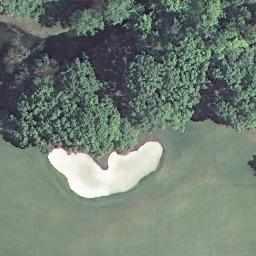

In [7]:
# B1: INPUT. None = random dataset image | a path = that image | upload your own (see comments)
IMAGE_PATH = None
# IMAGE_PATH = "/content/VLM/DATASETS/Satellite/forest_07.jpg"
# from google.colab import files; up = files.upload(); IMAGE_PATH = list(up)[0]

image_path, image, true_type = load_input(IMAGE_PATH)
print(f"File: {image_path.name} | size: {image.size} | true type: {true_type}")
display(image)

In [8]:
# B2: CLASSIFY (normal or satellite)
result = classify_image(image)
print("Predicted type :", result["label"])
print("Probabilities  : normal =", result["p_normal"], "| satellite =", result["p_satellite"])
if result["low_confidence"]:
    print("Warning: low confidence, this may be neither a clear photo nor a satellite view")
if true_type:
    print("True type      :", true_type, "->", "correct" if result["label"] == true_type else "WRONG")

Predicted type : satellite
Probabilities  : normal = 0.0 | satellite = 1.0
True type      : satellite -> correct


In [9]:
# B3: CAPTION + MATCH (uses the routed branch; set BRANCH manually to override)
BRANCH = result["label"]          # or "satellite" / "normal"
caps = add_match_scores(caption_image(image, BRANCH), image)
pd.set_option("display.max_colwidth", None)
display(caps)
if BRANCH == "satellite":
    print("Top land-use tags:", land_use_tags(image))
    if true_type == "satellite":
        print("Dataset class (reference):", image_path.name.rsplit("_", 1)[0])

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (18 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

,model,caption,seconds,clip_match,remoteclip_match
0,RSICD-BLIP,many green trees are around a piece of green meadow.,4.82,0.2419,0.1822
1,BLIP-base,an aerial view of a golf course,0.26,0.3286,0.3029
2,BLIP-large,aerial view of a golf course surrounded by trees and water,0.39,0.3293,0.3068


Top land-use tags: [('golf course or open green space', 0.913), ('water', 0.039), ('forest or trees', 0.02)]
Dataset class (reference): golfcourse


In [10]:
# B4: HIERARCHICAL CAPTION (satellite only)
print("Processing:", image_path.name)
if BRANCH == "satellite":
    h = hierarchical_caption(image)
    print("\nPARAGRAPH:", h["paragraph"])
    print("\nSENTENCES:"); [print(" -", s) for s in h["sentences"]]
    print("\nKEYWORDS (raw)     :", h["keywords_raw"])
    print("KEYWORDS (verified):", h["keywords"])
    print("\nRemoteCLIP match by level:", {k: v for k, v in h.items() if k.startswith("score")})
else:
    print("Hierarchy is for satellite images. Set BRANCH = 'satellite' in B3 to force it.")

Processing: golfcourse_07.jpg


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(



PARAGRAPH: The satellite image shows a small, white island surrounded by green vegetation. The island appears to be a natural formation, possibly a small sandbar or a submerged rock, with no visible buildings, roads, or water bodies. The surrounding area is covered in dense green trees, indicating a forested or wooded area.

SENTENCES:
 - The satellite image shows a small, white island surrounded by green vegetation.
 - The island appears to be a natural formation, possibly a small sandbar or a submerged rock, with no visible buildings, roads, or water bodies.
 - The surrounding area is covered in dense green trees, indicating a forested or wooded area.

KEYWORDS (raw)     : ['building', 'road', 'tree', 'vegetation', 'water', 'golf course or open green space', 'forest or trees']
KEYWORDS (verified): ['tree', 'vegetation', 'golf course or open green space']

RemoteCLIP match by level: {'score_paragraph': 0.2737, 'score_sentence': 0.26, 'score_keyword': 0.262}


## C. Experiments (on demand, slow; each cell is independent once Section A has run)

In [11]:
# C1: BATCH BASELINE. Router + captions + tags + scores (final run = all 100 images)
N_PER_BRANCH = None   # None = all 100 images (final run); use 5 for a quick test

paths = sample_paths(N_PER_BRANCH)
print(f"Running {len(paths)} images")
_w = load_input(paths[0])[1]; caption_image(_w, "normal"); caption_image(_w, "satellite")   # warm-up for fair timing
if device == "cuda": torch.cuda.reset_peak_memory_stats()

rows_img, rows_cap = [], []
for p in tqdm(paths):
    image_path_, img, true_type_ = load_input(p)
    category = image_path_.name.rsplit("_", 1)[0]
    r = classify_image(img); branch = r["label"]
    row = {"image": image_path_.name, "true_type": true_type_, "category": category,
           "router_pred": branch, "p_satellite": r["p_satellite"], "router_correct": branch == true_type_}
    if branch == "satellite":
        tags = land_use_tags(img, 3)
        row["top_tags"] = "; ".join(f"{t}({s})" for t, s in tags)
        expected = CLASS_TO_TAG.get(category)
        if expected:
            row["tag_top1"] = tags[0][0] == expected
            row["tag_top3"] = expected in [t for t, _ in tags]
    rows_img.append(row)

    caps = add_match_scores(caption_image(img, branch), img)
    kws = KEYWORDS.get(category, [])
    caps["keyword_hit"] = [any(k in c.lower() for k in kws) for c in caps["caption"]]
    caps["is_pipeline_output"] = caps["model"] == PIPELINE_MODEL[branch]
    for col, val in [("branch", branch), ("category", category), ("true_type", true_type_), ("image", image_path_.name)]:
        caps.insert(0, col, val)
    rows_cap.append(caps)

img_df, cap_df = pd.DataFrame(rows_img), pd.concat(rows_cap, ignore_index=True)
img_df.to_csv(OUT / "batch_images.csv", index=False)
cap_df.to_csv(OUT / "batch_captions.csv", index=False)

print("\nROUTER accuracy:", round(img_df["router_correct"].mean(), 3),
      "| misrouted:", img_df.loc[~img_df["router_correct"], "image"].tolist())
if "tag_top1" in img_df:
    t = img_df.dropna(subset=["tag_top1"])
    print(f"TAGS (satellite): top-1 = {t['tag_top1'].mean():.3f} | top-3 = {t['tag_top3'].mean():.3f} | n = {len(t)}")

# captioners compared on CORRECTLY routed images, grouped by true type (fair comparison)
ok = cap_df[cap_df["true_type"] == cap_df["branch"]]
summary = (ok.groupby(["true_type", "model"])
           .agg(n=("image", "count"), clip_match=("clip_match", "mean"), remoteclip_match=("remoteclip_match", "mean"),
                keyword_hit=("keyword_hit", "mean"), seconds=("seconds", "mean")).round(3))
summary.to_csv(OUT / "batch_summary.csv")
print("\nCAPTION SUMMARY (correctly routed images only):"); display(summary)
if device == "cuda":
    print(f"Peak VRAM: {torch.cuda.max_memory_allocated()/1e9:.2f} GB (includes Qwen if A6 was run)")
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
display(cap_df[["image", "branch", "model", "caption", "clip_match", "remoteclip_match", "keyword_hit"]])

Running 100 images


  0%|          | 0/100 [00:00<?, ?it/s]


ROUTER accuracy: 0.97 | misrouted: ['building_03.jpg', 'cafe_02.jpg', 'supermarket_04.jpg']
TAGS (satellite): top-1 = 0.843 | top-3 = 1.000 | n = 70

CAPTION SUMMARY (correctly routed images only):


n  clip_match  remoteclip_match  keyword_hit  seconds
true_type model                                                             
normal    BLIP-base   27       0.274             0.277        0.852    0.251
          BLIP-large  27       0.280             0.283        0.815    0.343
satellite BLIP-base   70       0.306             0.272        0.771    0.251
          BLIP-large  70       0.304             0.278        0.843    0.337
          RSICD-BLIP  70       0.267             0.270        0.871    0.305

Peak VRAM: 7.64 GB (includes Qwen if A6 was run)


,image,branch,model,caption,clip_match,remoteclip_match,keyword_hit
0,building_01.jpg,normal,BLIP-base,the sky is cloudy,0.2044,0.2483,False
1,building_01.jpg,normal,BLIP-large,there is a large building that has a lot of stairs in front of it,0.2500,0.2783,True
2,building_02.jpg,normal,BLIP-base,a red bus driving down a street next to tall buildings,0.2910,0.2886,True
3,building_02.jpg,normal,BLIP-large,there are many buses that are parked on the side of the road,0.2427,0.3170,False
4,building_03.jpg,satellite,RSICD-BLIP,two buildings are close to a park with some green trees and a swimming pool.,0.2414,0.2557,True
...,...,...,...,...,...,...,...
268,mediumresidential_09.jpg,satellite,BLIP-base,an aerial view of a street in a small town,0.2907,0.2786,False
269,mediumresidential_09.jpg,satellite,BLIP-large,an aerial view of a small town with a street and several buildings,0.2732,0.2880,True
270,mediumresidential_10.jpg,satellite,RSICD-BLIP,many green buildings and trees are located in an average residential area.,0.2905,0.2680,True
271,mediumresidential_10.jpg,satellite,BLIP-base,an aerial view of a neighborhood,0.3093,0.2634,False


In [12]:
# C2: HIERARCHY + RETRIEVAL EVALUATION (satellite, all 70 images)
N_HIER = None   # None = all 70 satellite images (final run, ~7-10 min); use 10 for a quick test

sat_paths = [p for p in sorted(DATA_ROOT.rglob("*")) if p.suffix.lower() in EXTS and "Satellite" in p.parts]
if N_HIER:
    sat_paths = sorted(random.Random(42).sample(sat_paths, N_HIER))

Q = {m: [] for m in ["Paragraph", "Sentences", "Keywords (verified)", "Hierarchy fusion", "RSICD-BLIP", "BLIP-base", "BLIP-large"]}
G, cats, rows = [], [], []

for p in tqdm(sat_paths):
    _, img, _ = load_input(p)
    cat = p.name.rsplit("_", 1)[0]; cats.append(cat)
    G.append(emb_images([img], rc_model, rc_preprocess)[0])

    h = hierarchical_caption(img)
    e_par = unit(emb_text([h["paragraph"]], rc_model, rc_tokenizer)[0])
    e_sen = unit(emb_text(h["sentences"], rc_model, rc_tokenizer).mean(0))
    e_key = unit(emb_text(["a satellite image with " + ", ".join(h["keywords"])], rc_model, rc_tokenizer)[0])
    Q["Paragraph"].append(e_par); Q["Sentences"].append(e_sen)
    Q["Keywords (verified)"].append(e_key); Q["Hierarchy fusion"].append(unit(e_par + e_sen + e_key))   # simple average, no training

    caps = caption_image(img, "satellite").set_index("model")["caption"]
    for name in ["RSICD-BLIP", "BLIP-base", "BLIP-large"]:
        Q[name].append(unit(emb_text([caps[name]], rc_model, rc_tokenizer)[0]))

    kw = KEYWORDS.get(cat, [])
    has = lambda text: any(k in text.lower() for k in kw)
    rows.append({"image": p.name, "category": cat, "paragraph": h["paragraph"], "sentences": " | ".join(h["sentences"]),
                 "keywords_raw": ", ".join(h["keywords_raw"]), "keywords_verified": ", ".join(h["keywords"]),
                 "n_kw_raw": len(h["keywords_raw"]), "n_kw_verified": len(h["keywords"]),
                 "hit_paragraph": has(h["paragraph"]), "hit_kw_raw": has(" ".join(h["keywords_raw"])),
                 "hit_kw_verified": has(" ".join(h["keywords"])), "hit_rsicd": has(caps["RSICD-BLIP"]),
                 "hit_blip_large": has(caps["BLIP-large"]), "score_paragraph": h["score_paragraph"],
                 "score_sentence": h["score_sentence"], "score_keyword": h["score_keyword"]})

# each generated text is a query for its own image
G, cats = np.stack(G), np.array(cats)
n, metrics = len(G), []
for m, vecs in Q.items():
    S = np.stack(vecs) @ G.T
    ranks = (S > S.diagonal()[:, None]).sum(1) + 1
    top5 = np.argsort(-S, axis=1)[:, :5]
    metrics.append({"query text": m, "R@1": (ranks <= 1).mean(), "R@5": (ranks <= 5).mean(), "R@10": (ranks <= 10).mean(),
                    "MRR": (1 / ranks).mean(), "P@5 same class": np.mean([(cats[top5[i]] == cats[i]).mean() for i in range(n)])})

hier_df, ret_df = pd.DataFrame(rows), pd.DataFrame(metrics).set_index("query text").round(3)
hier_df.to_csv(OUT / "hierarchy_captions.csv", index=False); ret_df.to_csv(OUT / "hierarchy_retrieval.csv")
print(f"Gallery size: {n} images (small galleries make retrieval look easy)")
print("\nRETRIEVAL (text -> image):"); display(ret_df)
print("\nKEYWORD HIT RATE:"); display(hier_df[["hit_paragraph", "hit_kw_raw", "hit_kw_verified", "hit_rsicd", "hit_blip_large"]].mean().round(3))
print("AVG #KEYWORDS raw -> verified:", round(hier_df["n_kw_raw"].mean(), 1), "->", round(hier_df["n_kw_verified"].mean(), 1))
display(hier_df[["image", "paragraph", "keywords_verified"]].head(5))

  0%|          | 0/70 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Gallery size: 70 images (small galleries make retrieval look easy)

RETRIEVAL (text -> image):


,R@1,R@5,R@10,MRR,P@5 same class
query text,,,,,
Paragraph,0.214,0.600,0.786,0.367,0.674
Sentences,0.143,0.571,0.700,0.330,0.620
Keywords (verified),0.071,0.443,0.643,0.248,0.569
Hierarchy fusion,0.214,0.557,0.757,0.370,0.651
RSICD-BLIP,0.157,0.500,0.714,0.326,0.649
BLIP-base,0.057,0.314,0.586,0.197,0.560
BLIP-large,0.129,0.443,0.700,0.284,0.609



KEYWORD HIT RATE:


,0
hit_paragraph,0.986
hit_kw_raw,1.000
hit_kw_verified,1.000
hit_rsicd,0.871
hit_blip_large,0.843


AVG #KEYWORDS raw -> verified: 7.4 -> 6.4


,image,paragraph,keywords_verified
0,buildings_01.jpg,"The satellite image shows a large building with a flat roof and a series of white vertical columns on the left side. The building has a parking lot with numerous cars parked in rows. The image is taken from an aerial perspective, providing a clear view of the structure and its surroundings.","building, parking lot, car, buildings, commercial buildings, road intersection"
1,buildings_02.jpg,"The satellite image shows a complex of buildings with multiple levels and structures. There are several cars parked on the streets, and some of the buildings have visible windows and doors. The image also shows a tree in the middle of the complex, providing a contrast to the otherwise urban setting. The overall scene appears to be a mix of residential and commercial buildings.","building, residential, commercial, street, car, tree, buildings, commercial buildings, dense residential area"
2,buildings_03.jpg,"The satellite image shows a large, multi-story building with a red roof. The building has several windows and appears to be a commercial or residential structure. There are several cars parked in front of the building, and the street is lined with trees and buildings. The image is slightly blurry, indicating it might be taken from a distance or with a low resolution camera.","building, residential, commercial, street, car, tree, buildings, dense residential area, commercial buildings"
3,buildings_04.jpg,"The satellite image shows a complex of buildings with multiple roofs. The roofs are mostly flat, and some have small windows or vents. There are several vehicles parked on the streets, and the buildings appear to be of different sizes and shapes. The image does not show any water bodies or vegetation.","building, street, vegetation, buildings, commercial buildings, dense residential area"
4,buildings_05.jpg,"The satellite image shows a complex of buildings with multiple roofs. The roofs are covered with dark tiles, and the buildings have a mix of windows and doors. The image is taken from an aerial perspective, providing a bird's-eye view of the structures.","building, buildings, commercial buildings, dense residential area"


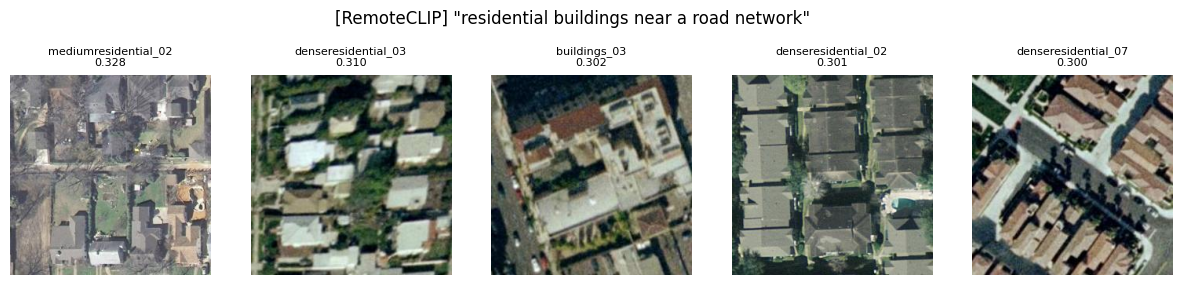

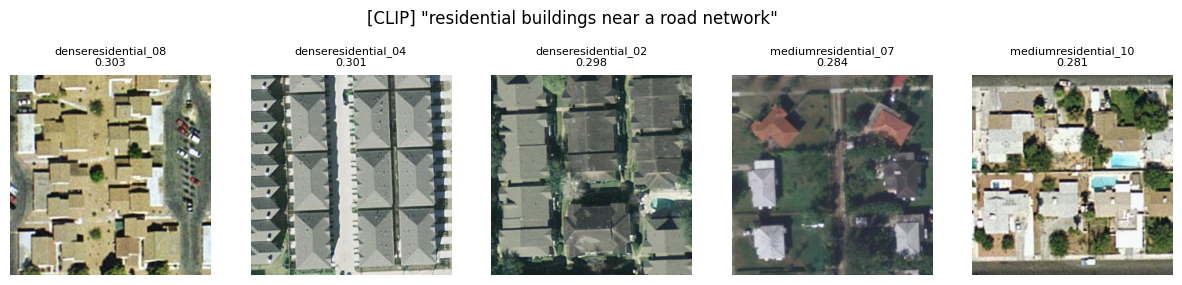

P@5             R@10               AP           
model                                     CLIP RemoteCLIP  CLIP RemoteCLIP  CLIP RemoteCLIP
query                                                                                      
a dense forest                             1.0        1.0  0.90        1.0  0.98       1.00
a freeway or highway with cars             0.8        1.0  0.60        0.9  0.78       0.93
a golf course                              1.0        1.0  1.00        1.0  1.00       1.00
a large green space with trees             0.8        1.0  0.40        0.5  0.78       0.93
a road intersection                        1.0        1.0  0.80        1.0  0.94       1.00
dense residential buildings                1.0        1.0  0.60        0.5  0.76       0.71
houses with trees and yards                1.0        1.0  0.45        0.5  0.91       0.90
residential buildings near a road network  1.0        0.8  0.30        0.3  0.86       0.84

MEAN:


,P@5,R@10,AP
model,,,
CLIP,0.950,0.631,0.877
RemoteCLIP,0.975,0.712,0.913


In [13]:
# C3: TEXT-QUERY IMAGE SEARCH over the 70 satellite images (application 5): RemoteCLIP vs general CLIP
sat_paths_s = sorted(p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS and "Satellite" in p.parts)
sat_imgs = [Image.open(p).convert("RGB") for p in sat_paths_s]
sat_cats = np.array([p.name.rsplit("_", 1)[0] for p in sat_paths_s])

ENC = {"RemoteCLIP": (rc_model, rc_preprocess, rc_tokenizer), "CLIP": (clip_model, clip_preprocess, clip_tokenizer)}
GAL = {name: emb_images(sat_imgs, m, pre) for name, (m, pre, _) in ENC.items()}   # embed once

def search(query, model_name="RemoteCLIP", k=5, show=True):
    m, _, tok = ENC[model_name]
    sims = GAL[model_name] @ emb_text([query], m, tok)[0]
    idx = np.argsort(-sims)[:k]
    if show:
        fig, axes = plt.subplots(1, k, figsize=(3 * k, 3.4))
        for ax, i in zip(axes, idx):
            ax.imshow(sat_imgs[i]); ax.axis("off"); ax.set_title(f"{sat_paths_s[i].stem}\n{sims[i]:.3f}", fontsize=8)
        fig.suptitle(f'[{model_name}] "{query}"'); plt.show()
    return idx, sims

for mn in ENC:
    search("residential buildings near a road network", mn)

# relevant classes per query: CHECK/EDIT these by hand before reporting numbers
QUERIES = {
    "dense residential buildings": ["denseresidential"],
    "houses with trees and yards": ["mediumresidential", "denseresidential"],
    "a road intersection": ["intersection"],
    "a freeway or highway with cars": ["freeway"],
    "a large green space with trees": ["forest", "golfcourse"],
    "a golf course": ["golfcourse"],
    "a dense forest": ["forest"],
    "residential buildings near a road network": ["denseresidential", "mediumresidential", "intersection"],
}
rows = []
for q, rel_classes in QUERIES.items():
    rel = np.isin(sat_cats, rel_classes)
    for mn in ENC:
        _, sims = search(q, mn, show=False)
        hits = rel[np.argsort(-sims)]
        rows.append({"query": q, "model": mn, "P@5": hits[:5].mean(), "R@10": hits[:10].sum() / rel.sum(),
                     "AP": np.mean([hits[:i + 1].mean() for i in np.where(hits)[0]])})
res = pd.DataFrame(rows)
display(res.pivot(index="query", columns="model", values=["P@5", "R@10", "AP"]).round(2))
print("MEAN:"); display(res.groupby("model")[["P@5", "R@10", "AP"]].mean().round(3))
res.to_csv(OUT / "text_query_retrieval.csv", index=False)

In [14]:
# C4: DOWNLOAD all result files as a zip (Colab deletes files when the session ends)
import shutil
from google.colab import files
shutil.make_archive("/content/results", "zip", OUT)
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# C5: PUSH results to GitHub. Needs a Colab Secret named GITHUB_TOKEN (fine-grained, Contents: read and write)
from google.colab import userdata
try:
    TOKEN = userdata.get("GITHUB_TOKEN")
except userdata.SecretNotFoundError:
    TOKEN = None
    print("❌ ERROR: 'GITHUB_TOKEN' secret not found in Google Colab Secrets.")
    print("To fix this: Click the key icon (🔑) on the left sidebar, add 'GITHUB_TOKEN', paste your token, and enable Notebook access.")

if TOKEN:
    GIT_NAME, GIT_EMAIL = "Your Name", "your_email@example.com"          # <- edit
    AUTH = "Authorization: Basic " + base64.b64encode(f"x-access-token:{TOKEN}".encode()).decode()

    def git(*args, auth=False):
        cmd = ["git", "-C", str(ROOT)]
        if auth: cmd += ["-c", f"http.extraheader={AUTH}"]
        r = subprocess.run(cmd + list(args), capture_output=True, text=True)
        print((r.stdout + r.stderr).replace(TOKEN, "***").replace(AUTH, "***").strip())

    git("add", "outputs/")
    git("-c", f"user.name={GIT_NAME}", "-c", f"user.email={GIT_EMAIL}", "commit", "-m", "Add experiment results")
    git("pull", "--rebase", auth=True)
    git("push", auth=True)

❌ ERROR: 'GITHUB_TOKEN' secret not found in Google Colab Secrets.
To fix this: Click the key icon (🔑) on the left sidebar, add 'GITHUB_TOKEN', paste your token, and enable Notebook access.


## D. Results and report (run after C1 on ALL images, C2 on ALL images, and C3)
Run D0 to D6 in order. Each cell prints a table with the metrics for your report and saves a file in `outputs/`.
D4a/D4b need ~20 hand-written reference captions (about 20 minutes). D5 needs a quick eyeball check of ~10 paragraphs. Run D5b before D6, and run C3 before the D7 demo.

In [17]:
# D0: load results from memory (or from the saved CSVs) and check they cover the full dataset
def _get(name, csv, **kw):
    return globals()[name] if name in globals() else pd.read_csv(OUT / csv, **kw)

img_df  = _get("img_df",  "batch_images.csv")
cap_df  = _get("cap_df",  "batch_captions.csv")
hier_df = _get("hier_df", "hierarchy_captions.csv")
ret_df  = _get("ret_df",  "hierarchy_retrieval.csv", index_col=0)
res     = _get("res",     "text_query_retrieval.csv")
print(f"images: {len(img_df)} (expect 100) | caption rows: {len(cap_df)} | hierarchy images: {len(hier_df)} (expect 70) | search queries: {res['query'].nunique()}")
if len(img_df) < 100 or len(hier_df) < 70:
    print("WARNING: set N_PER_BRANCH = None in C1 and N_HIER = None in C2, rerun them, then rerun D0 for final numbers")

images: 100 (expect 100) | caption rows: 273 | hierarchy images: 70 (expect 70) | search queries: 8


,router
images,100.000
accuracy,0.970
precision (satellite),0.959
recall (satellite),1.000
F1 (satellite),0.979
recall (normal),0.900
ROC-AUC,1.000


Misrouted images: [{'image': 'building_03.jpg', 'true_type': 'normal', 'p_satellite': 0.765}, {'image': 'cafe_02.jpg', 'true_type': 'normal', 'p_satellite': 0.618}, {'image': 'supermarket_04.jpg', 'true_type': 'normal', 'p_satellite': 0.599}]


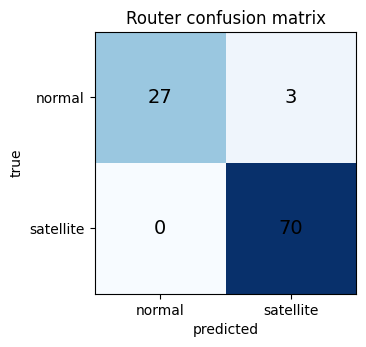

Note: normal-vs-satellite is an easy task (different viewpoints). Report it as image-source classification.


In [18]:
# D1: ROUTER metrics (normal vs satellite)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix

y_true = (img_df["true_type"] == "satellite").astype(int).values
y_pred = (img_df["router_pred"] == "satellite").astype(int).values
p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
router_metrics = pd.Series({
    "images": len(y_true), "accuracy": accuracy_score(y_true, y_pred),
    "precision (satellite)": p, "recall (satellite)": r, "F1 (satellite)": f,
    "recall (normal)": tn / (tn + fp) if (tn + fp) else np.nan,
    "ROC-AUC": roc_auc_score(y_true, img_df["p_satellite"]) if len(set(y_true)) == 2 else np.nan}).round(3)
display(router_metrics.to_frame("router"))
print("Misrouted images:", img_df.loc[img_df["router_pred"] != img_df["true_type"], ["image", "true_type", "p_satellite"]].to_dict("records"))

fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "satellite"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "satellite"])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Router confusion matrix")
plt.savefig(OUT / "fig_router_confusion.png", dpi=150, bbox_inches="tight"); plt.show()
router_metrics.to_csv(OUT / "router_metrics.csv")
print("Note: normal-vs-satellite is an easy task (different viewpoints). Report it as image-source classification.")

In [19]:
# D2: LAND-USE TAGGING metrics (RemoteCLIP zero-shot, satellite images)
from sklearn.metrics import classification_report

sat = img_df[img_df["true_type"] == "satellite"].copy()
sat["expected"] = sat["category"].map(CLASS_TO_TAG)
sat["pred_top1"] = (sat["top_tags"].fillna("").str.split(";").str[0]
                    .str.replace(r"\s*\([^)]*\)\s*$", "", regex=True).str.strip())
sat["top3_hit"] = sat["tag_top3"].fillna(False).astype(bool)

print(f"Top-1 accuracy: {(sat['expected'] == sat['pred_top1']).mean():.3f} | Top-3 hit rate: {sat['top3_hit'].mean():.3f} | n = {len(sat)}")
tag_rep = pd.DataFrame(classification_report(sat["expected"], sat["pred_top1"], labels=sorted(sat["expected"].unique()),
                                             output_dict=True, zero_division=0)).T.round(3)
display(tag_rep)
print("Confusion (rows = true class, columns = predicted tag):")
display(pd.crosstab(sat["expected"], sat["pred_top1"].replace("", "(not routed)")))
tag_rep.to_csv(OUT / "tag_metrics.csv")

Top-1 accuracy: 0.843 | Top-3 hit rate: 1.000 | n = 70


/tmp/ipykernel_359/2564269112.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sat["top3_hit"] = sat["tag_top3"].fillna(False).astype(bool)


,precision,recall,f1-score,support
buildings,0.909,1.000,0.952,10.000
dense residential area,0.471,0.800,0.593,10.000
forest or trees,1.000,1.000,1.000,10.000
freeway or highway,1.000,1.000,1.000,10.000
golf course or open green space,1.000,1.000,1.000,10.000
medium density residential area,1.000,0.100,0.182,10.000
road intersection,0.909,1.000,0.952,10.000
accuracy,0.843,0.843,0.843,0.843
macro avg,0.898,0.843,0.811,70.000
weighted avg,0.898,0.843,0.811,70.000


Confusion (rows = true class, columns = predicted tag):


pred_top1,buildings,dense residential area,forest or trees,freeway or highway,golf course or open green space,medium density residential area,road intersection
expected,,,,,,,
buildings,10,0,0,0,0,0,0
dense residential area,1,8,0,0,0,0,1
forest or trees,0,0,10,0,0,0,0
freeway or highway,0,0,0,10,0,0,0
golf course or open green space,0,0,0,0,10,0,0
medium density residential area,0,9,0,0,0,1,0
road intersection,0,0,0,0,0,0,10


In [20]:
# D3: CAPTION comparison on correctly routed images + significance + MiniLM agreement
%pip install -q sentence-transformers
import itertools
from sentence_transformers import SentenceTransformer

ok = cap_df[cap_df["true_type"] == cap_df["branch"]].copy().reset_index(drop=True)
ok["keyword_hit"] = ok["keyword_hit"].astype(float)

agg = ok.groupby(["true_type", "model"]).agg(n=("image", "count"), clip_match=("clip_match", "mean"),
        remoteclip_match=("remoteclip_match", "mean"), keyword_hit=("keyword_hit", "mean"), seconds=("seconds", "mean"))
n_img = ok.groupby("true_type")["image"].nunique()
wins = ok.loc[ok.groupby("image")["remoteclip_match"].idxmax()].groupby(["true_type", "model"]).size()
agg["win_rate (RemoteCLIP match)"] = [wins.get(ix, 0) / n_img[ix[0]] for ix in agg.index]
caption_table = agg.round(3)
print("CAPTION METRICS (means; win_rate = share of images where the model has the best RemoteCLIP match)")
display(caption_table); caption_table.to_csv(OUT / "caption_metrics.csv")

def paired_bootstrap(a, b, n=5000, seed=0):
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    boots = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    return round(float(d.mean()), 4), np.round(np.percentile(boots, [2.5, 97.5]), 4)

rows = []
for t, (m1, m2) in {"satellite": ("RSICD-BLIP", "BLIP-large"), "normal": ("BLIP-large", "BLIP-base")}.items():
    sub = ok[ok["true_type"] == t]
    for metric in ["remoteclip_match", "clip_match", "keyword_hit"]:
        pv = sub.pivot(index="image", columns="model", values=metric)
        if m1 in pv and m2 in pv:
            d, (lo, hi) = paired_bootstrap(pv[m1], pv[m2])
            rows.append({"comparison": f"{t}: {m1} minus {m2}", "metric": metric, "mean diff": d,
                         "95% CI": f"[{lo}, {hi}]", "clearly different": bool(lo > 0 or hi < 0)})
sig_table = pd.DataFrame(rows)
print("\nPAIRED BOOTSTRAP (if the CI includes 0, the difference is not clear)")
display(sig_table); sig_table.to_csv(OUT / "caption_significance.csv", index=False)

minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
E = minilm.encode(ok["caption"].tolist(), normalize_embeddings=True, show_progress_bar=False)
idx = {(im, m): i for i, (im, m) in enumerate(zip(ok["image"], ok["model"]))}
agree = []
for t in ok["true_type"].unique():
    sub = ok[ok["true_type"] == t]
    for a, b in itertools.combinations(sorted(sub["model"].unique()), 2):
        sims = [float(E[idx[(im, a)]] @ E[idx[(im, b)]]) for im in sub["image"].unique() if (im, a) in idx and (im, b) in idx]
        agree.append({"type": t, "model pair": f"{a} vs {b}", "MiniLM cosine agreement": round(float(np.mean(sims)), 3)})
agree_table = pd.DataFrame(agree)
print("\nCROSS-MODEL AGREEMENT (all-MiniLM-L6-v2 cosine between captions of the same image)")
display(agree_table); agree_table.to_csv(OUT / "caption_agreement.csv", index=False)

CAPTION METRICS (means; win_rate = share of images where the model has the best RemoteCLIP match)


n  clip_match  remoteclip_match  keyword_hit  seconds  win_rate (RemoteCLIP match)
true_type model                                                                                          
normal    BLIP-base   27       0.274             0.277        0.852    0.251                        0.481
          BLIP-large  27       0.280             0.283        0.815    0.343                        0.519
satellite BLIP-base   70       0.306             0.272        0.771    0.251                        0.214
          BLIP-large  70       0.304             0.278        0.843    0.337                        0.386
          RSICD-BLIP  70       0.267             0.270        0.871    0.305                        0.400


PAIRED BOOTSTRAP (if the CI includes 0, the difference is not clear)


,comparison,metric,mean diff,95% CI,clearly different
0,satellite: RSICD-BLIP minus BLIP-large,remoteclip_match,-0.0077,"[-0.0187, 0.0036]",False
1,satellite: RSICD-BLIP minus BLIP-large,clip_match,-0.0367,"[-0.0442, -0.0293]",True
2,satellite: RSICD-BLIP minus BLIP-large,keyword_hit,0.0286,"[-0.0714, 0.1286]",False
3,normal: BLIP-large minus BLIP-base,remoteclip_match,0.0057,"[-0.0026, 0.0141]",False
4,normal: BLIP-large minus BLIP-base,clip_match,0.0061,"[-0.0032, 0.0161]",False
5,normal: BLIP-large minus BLIP-base,keyword_hit,-0.0370,"[-0.1852, 0.1111]",False


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

... (9 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


CROSS-MODEL AGREEMENT (all-MiniLM-L6-v2 cosine between captions of the same image)


,type,model pair,MiniLM cosine agreement
0,normal,BLIP-base vs BLIP-large,0.651
1,satellite,BLIP-base vs BLIP-large,0.765
2,satellite,BLIP-base vs RSICD-BLIP,0.366
3,satellite,BLIP-large vs RSICD-BLIP,0.411


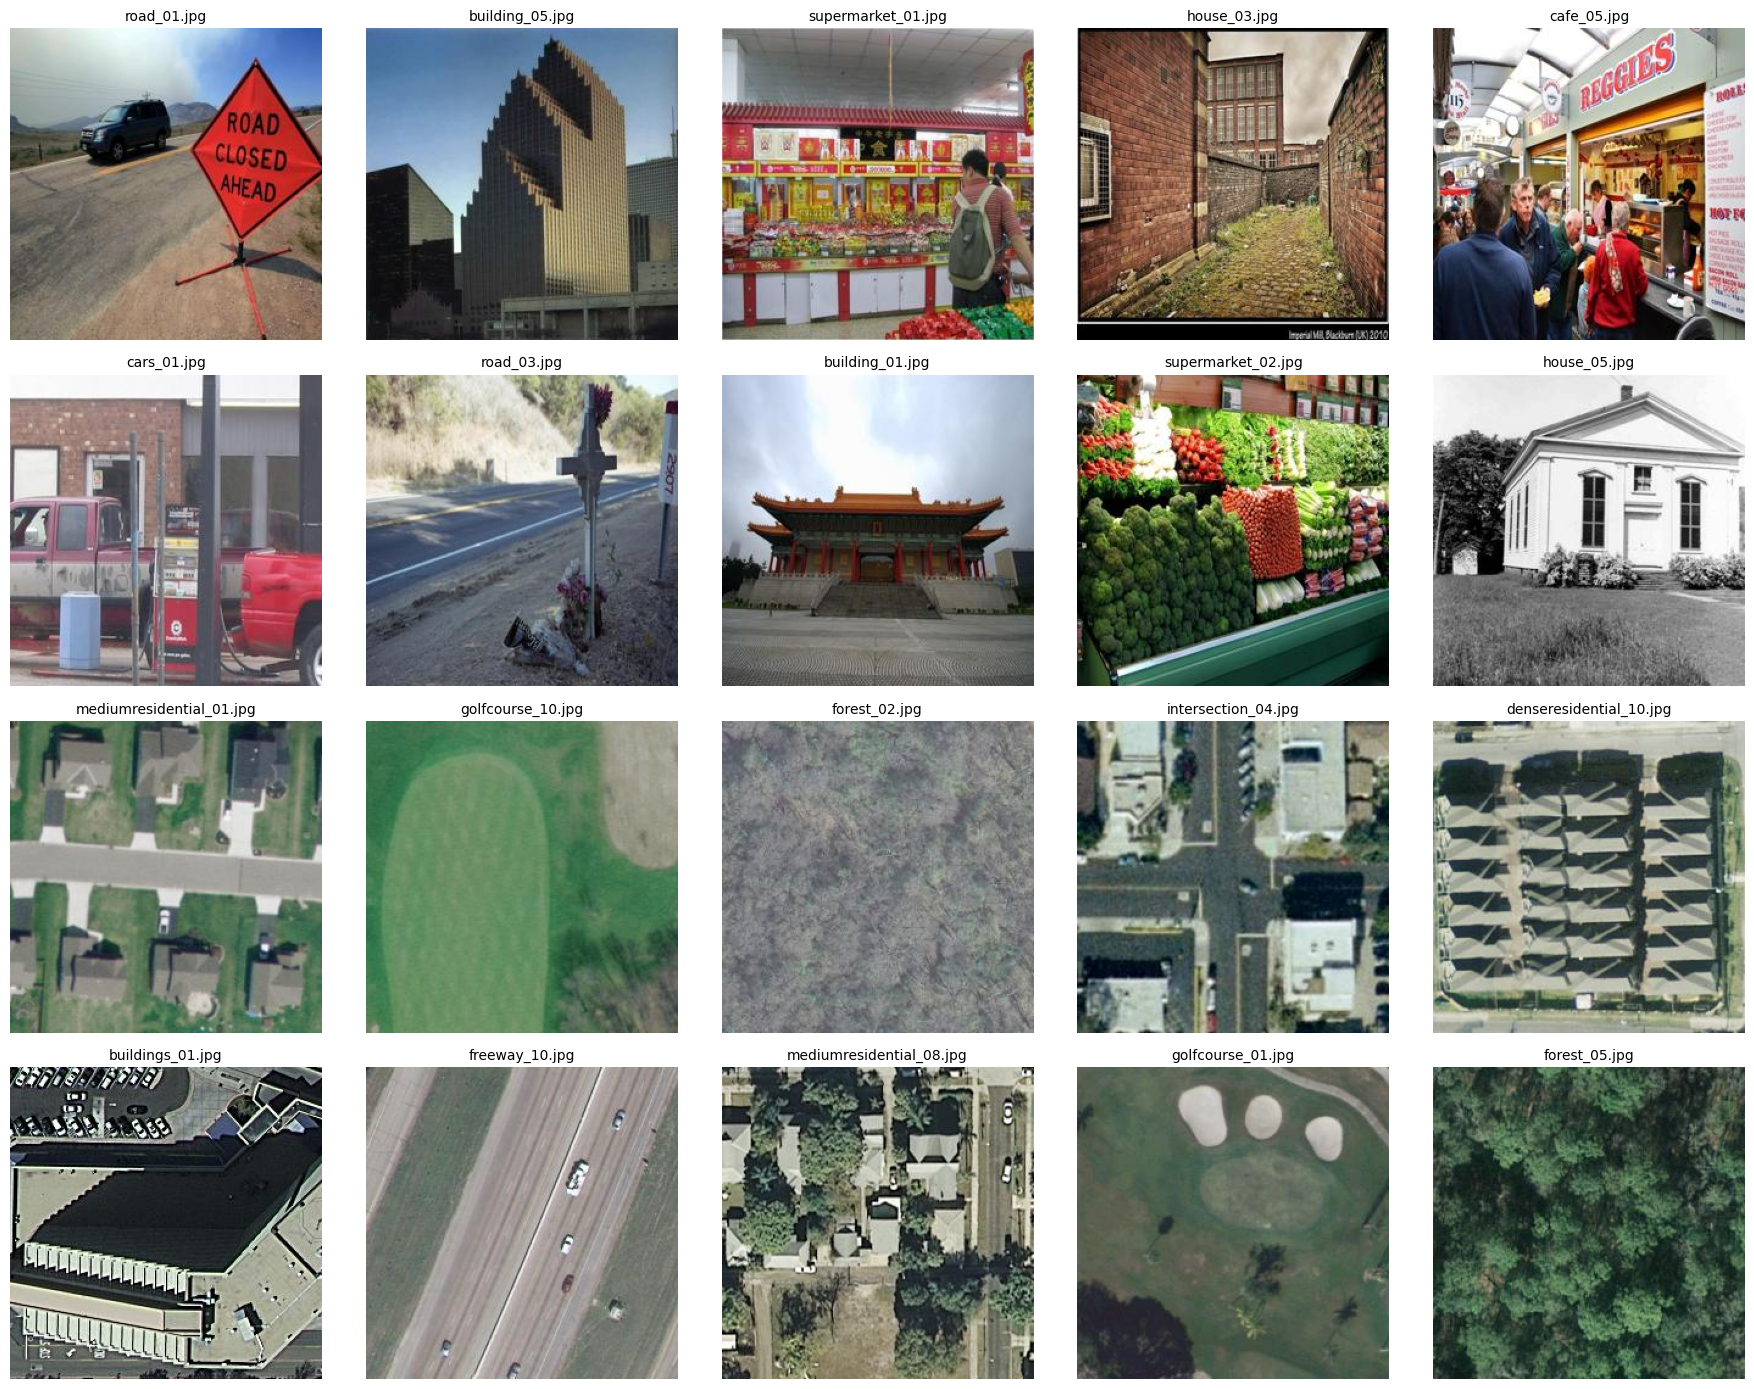

Copy this dict into D4b and write ONE plain sentence per image describing only what you can see:

REFS = {
    "road_01.jpg": "",
    "building_05.jpg": "",
    "supermarket_01.jpg": "",
    "house_03.jpg": "",
    "cafe_05.jpg": "",
    "cars_01.jpg": "",
    "road_03.jpg": "",
    "building_01.jpg": "",
    "supermarket_02.jpg": "",
    "house_05.jpg": "",
    "mediumresidential_01.jpg": "",
    "golfcourse_10.jpg": "",
    "forest_02.jpg": "",
    "intersection_04.jpg": "",
    "denseresidential_10.jpg": "",
    "buildings_01.jpg": "",
    "freeway_10.jpg": "",
    "mediumresidential_08.jpg": "",
    "golfcourse_01.jpg": "",
    "forest_05.jpg": "",
}


In [21]:
# D4a: pick 20 images (10 normal + 10 satellite) and show them so you can write ONE reference caption each
REF_N = 10
ref_paths = sample_paths(REF_N, seed=7)
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
for ax, p in zip(axes.flat, ref_paths):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(p.name, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
print("Copy this dict into D4b and write ONE plain sentence per image describing only what you can see:\n")
print("REFS = {\n" + "\n".join(f'    "{p.name}": "",' for p in ref_paths) + "\n}")

In [22]:
# D4b: REFERENCE-BASED metrics (BLEU, ROUGE-L, CIDEr, MiniLM similarity to your reference captions)
%pip install -q pycocoevalcap
import re
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

REFS = {}   # <- paste the dict printed by D4a here and fill in every sentence

REFS = {k: v for k, v in REFS.items() if v.strip()}
if not REFS:
    print("Fill REFS first (see D4a), then rerun this cell.")
else:
    norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", s.lower())).strip()
    ref_ok = ok[ok["image"].isin(REFS)]
    rows = []
    for (t, m), g in ref_ok.groupby(["true_type", "model"]):
        gts = {r.image: [norm(REFS[r.image])] for r in g.itertuples()}
        hyp = {r.image: [norm(r.caption)] for r in g.itertuples()}
        b, _ = Bleu(4).compute_score(gts, hyp, verbose=0)
        ro, _ = Rouge().compute_score(gts, hyp)
        ci, _ = Cider().compute_score(gts, hyp)
        er = minilm.encode([REFS[r.image] for r in g.itertuples()], normalize_embeddings=True, show_progress_bar=False)
        ec = minilm.encode([r.caption for r in g.itertuples()], normalize_embeddings=True, show_progress_bar=False)
        rows.append({"true_type": t, "model": m, "n": len(g), "BLEU-1": b[0], "BLEU-4": b[3], "ROUGE-L": ro,
                     "CIDEr": ci, "MiniLM sim to reference": float((er * ec).sum(1).mean())})
    ref_scores = pd.DataFrame(rows).set_index(["true_type", "model"]).round(3)
    display(ref_scores); ref_scores.to_csv(OUT / "reference_metrics.csv")
    print("Small n: treat these as indicative. CIDEr is unstable on ~10 images per type. Rely most on MiniLM similarity and ROUGE-L.")

Fill REFS first (see D4a), then rerun this cell.


RETRIEVAL by text level (each generated text is a query for its own image):


,R@1,R@5,R@10,MRR,P@5 same class
query text,,,,,
Paragraph,0.214,0.600,0.786,0.367,0.674
Sentences,0.143,0.571,0.700,0.330,0.620
Keywords (verified),0.071,0.443,0.643,0.248,0.569
Hierarchy fusion,0.214,0.557,0.757,0.370,0.651
RSICD-BLIP,0.157,0.500,0.714,0.326,0.649
BLIP-base,0.057,0.314,0.586,0.197,0.560
BLIP-large,0.129,0.443,0.700,0.284,0.609



KEYWORD HIT RATE:


,rate
hit_paragraph,0.986
hit_kw_raw,1.000
hit_kw_verified,1.000
hit_rsicd,0.871
hit_blip_large,0.843



Keyword verification removed 13.3% of raw keywords (7.4 -> 6.4 per image)
Mean RemoteCLIP score by level: {'score_paragraph': 0.2649, 'score_sentence': 0.2652, 'score_keyword': 0.2632}


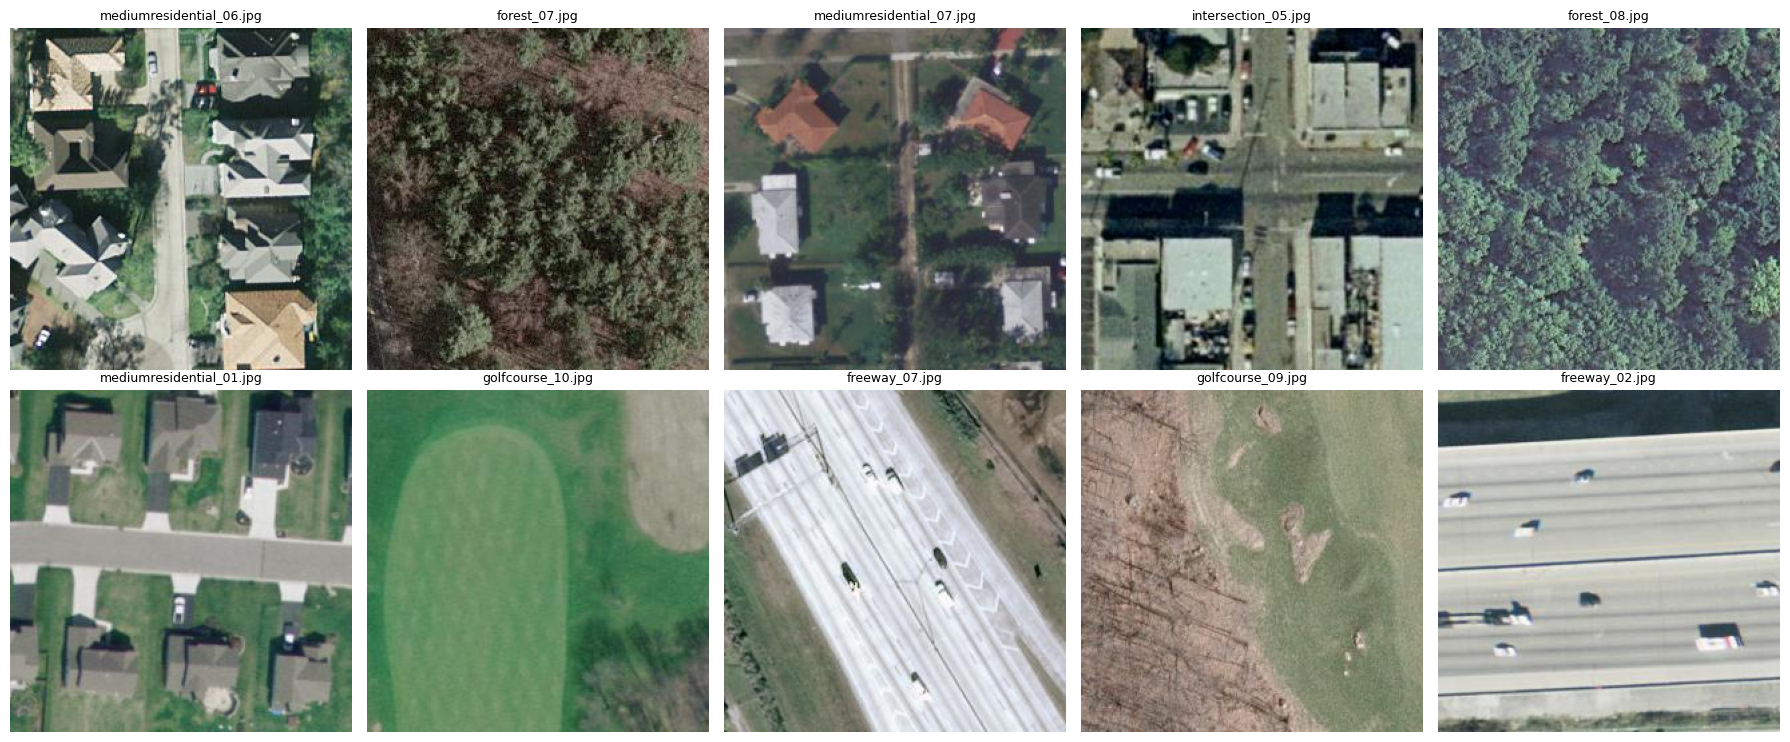

1. mediumresidential_06.jpg: This satellite image shows a residential neighborhood with several houses. The houses have different roof colors, and some have visible windows. There are also trees and grass in the yards. The street is narrow and appears to be made of asphalt. There are no visible vehicles or people in the image.

2. forest_07.jpg: The satellite image depicts a dense forest with a mix of green and brown patches. The trees are tall and spread out, indicating a mature forest. The ground appears to be covered with a mix of soil and vegetation, with some areas showing signs of erosion or disturbance. The overall scene suggests a natural, undisturbed forest environment.

3. mediumresidential_07.jpg: The satellite image shows a residential area with several houses. The houses have white roofs and are surrounded by green lawns. There are also some trees and bushes in the vicinity. The image is taken from an aerial perspective, providing a bird's-eye view of the neighborhood.

4.

In [23]:
# D5: HIERARCHY summary + hallucination check
print("RETRIEVAL by text level (each generated text is a query for its own image):"); display(ret_df.round(3))
print("\nKEYWORD HIT RATE:"); display(hier_df[["hit_paragraph", "hit_kw_raw", "hit_kw_verified", "hit_rsicd", "hit_blip_large"]].astype(float).mean().round(3).to_frame("rate"))
unsupported = 1 - hier_df["n_kw_verified"].sum() / hier_df["n_kw_raw"].sum()
print(f"\nKeyword verification removed {unsupported:.1%} of raw keywords ({hier_df['n_kw_raw'].mean():.1f} -> {hier_df['n_kw_verified'].mean():.1f} per image)")
print("Mean RemoteCLIP score by level:", hier_df[["score_paragraph", "score_sentence", "score_keyword"]].mean().round(4).to_dict())

# manual factual check: look at 10 paragraphs, mark 1 if the paragraph mentions something NOT visible in the image
chk = hier_df.sample(min(10, len(hier_df)), random_state=1).reset_index(drop=True)
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for ax, (_, row) in zip(axes.flat, chk.iterrows()):
    ax.imshow(Image.open(next(DATA_ROOT.rglob(row["image"]))).convert("RGB")); ax.set_title(row["image"], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
for i, row in chk.iterrows():
    print(f"{i+1}. {row['image']}: {row['paragraph']}\n")

HALLU = {}   # <- fill after looking: {"forest_09.jpg": 0, "denseresidential_05.jpg": 1, ...}  (1 = mentions something not visible)
if HALLU:
    hallu_rate = float(np.mean(list(HALLU.values())))
    print(f"Manual check: {int(sum(HALLU.values()))} of {len(HALLU)} paragraphs contain an invented detail ({hallu_rate:.0%})")

In [24]:
# D5b: REPRODUCIBILITY record (versions, models, seeds, settings, dataset counts); D6 includes it in the report
import json, platform
from importlib.metadata import version, PackageNotFoundError

def ver(p):
    try: return version(p)
    except PackageNotFoundError: return "not installed"

n_sat = sum(1 for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS and "Satellite" in p.parts)
n_norm = sum(1 for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS and "Satellite" not in p.parts)
commit = subprocess.run(["git", "-C", str(ROOT), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
repro = {
    "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "repo_commit": commit,
    "packages": {p: ver(p) for p in ["torch", "transformers", "open_clip_torch", "sentence-transformers",
                                     "scikit-learn", "pandas", "numpy", "pycocoevalcap", "gradio"]},
    "models": {"router_and_normal_matching": "OpenAI CLIP ViT-B-32-quickgelu (open_clip, pretrained=openai)",
               "normal_captioners": [BASE_R, LARGE_R], "satellite_captioner": BLIP_MODELS["RSICD-BLIP"][0],
               "remoteclip": "chendelong/RemoteCLIP, RemoteCLIP-ViT-B-32.pt",
               "hierarchy_mllm": "Qwen/Qwen2-VL-2B-Instruct", "caption_agreement": "sentence-transformers/all-MiniLM-L6-v2"},
    "settings": {"seeds": {"sample_paths": 42, "reference_sample": 7, "hallucination_sample": 1, "bootstrap": 0},
                 "blip_generation": {"max_new_tokens": 40, "num_beams": 3},
                 "qwen_generation": {"max_new_tokens": 150, "do_sample": False},
                 "router_prompts": {"normal": NORMAL_PROMPTS, "satellite": SAT_PROMPTS},
                 "landuse_tags": LANDUSE_TAGS, "qwen_prompt": PROMPT},
    "dataset": {"normal_images": n_norm, "satellite_images": n_sat},
}
(OUT / "reproducibility.json").write_text(json.dumps(repro, indent=2))
print(json.dumps(repro, indent=2)[:2500])

{
  "python": "3.13.16",
  "gpu": "Tesla T4",
  "repo_commit": "c3b6b62",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "5.22.1",
    "open_clip_torch": "4.2.2",
    "sentence-transformers": "5.7.0",
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "pycocoevalcap": "1.2",
    "gradio": "6.31.0"
  },
  "models": {
    "router_and_normal_matching": "OpenAI CLIP ViT-B-32-quickgelu (open_clip, pretrained=openai)",
    "normal_captioners": [
      "Salesforce/blip-image-captioning-base",
      "Salesforce/blip-image-captioning-large"
    ],
    "satellite_captioner": "Gurveer05/blip-image-captioning-base-rscid-finetuned",
    "remoteclip": "chendelong/RemoteCLIP, RemoteCLIP-ViT-B-32.pt",
    "hierarchy_mllm": "Qwen/Qwen2-VL-2B-Instruct",
    "caption_agreement": "sentence-transformers/all-MiniLM-L6-v2"
  },
  "settings": {
    "seeds": {
      "sample_paths": 42,
      "reference_sample": 7,
      "hallucination_sample": 1,
      "bootstrap": 

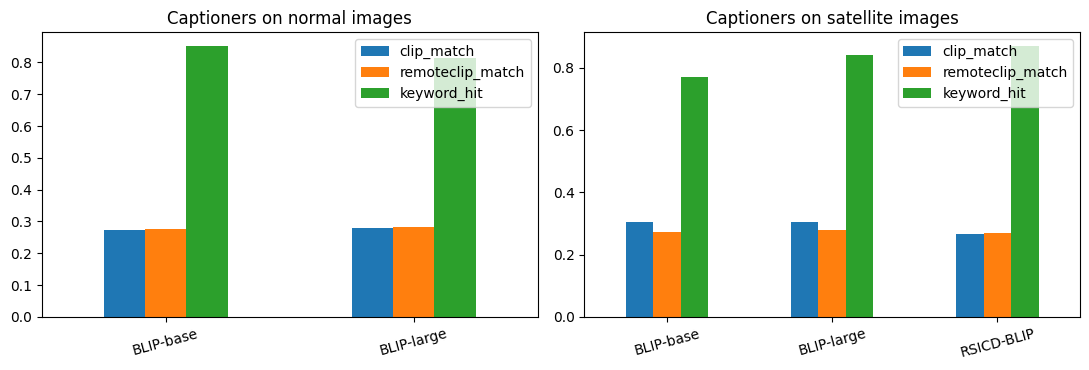

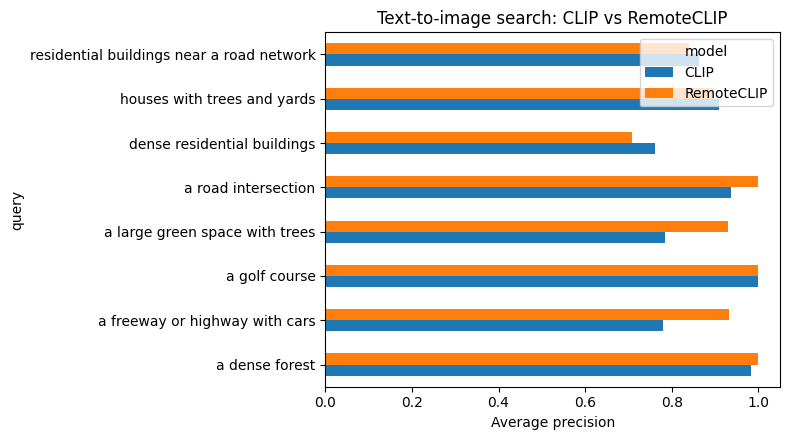

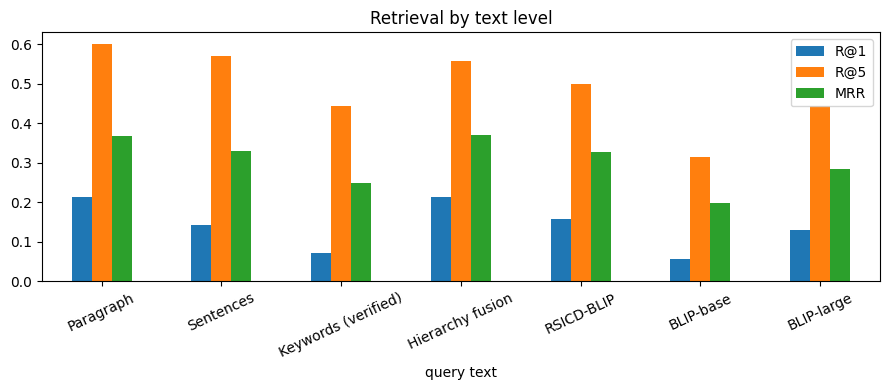

# NITPY results

## Pipeline
```mermaid
flowchart TD
  A[Input image] --> B[CLIP router]
  B -->|normal| C[BLIP-base / BLIP-large captions] --> D[CLIP matching]
  B -->|satellite| E[RSICD-BLIP + BLIP captions] --> F[RemoteCLIP tags, matching, text search]
  E --> G[Qwen2-VL-2B hierarchy: paragraph, sentences, keywords]
```
All models are pretrained and used as released (no training). Qwen2-VL-2B writes the paragraph; sentences and keywords are derived from it, and keywords are verified against the image with RemoteCLIP.

## Dataset
100 images: 30 normal urban (Places365) and 70 satellite (UC Merced, 7 classes).

## Router (image-source classification)
|                       |   router |
|:----------------------|---------:|
| images                |  100     |
| accuracy              |    0.97  |
| precision (satellite) |    0.959 |
| recall (satellite)    |    1     |
| F1 (satellite)        |    0.979 |
| recall (normal)       |    0.9   |
| ROC-AUC               |    1     |

## Lan

In [25]:
# D6: FIGURES + final_results.md (paste into your README / slides)
cap_plot = caption_table.reset_index()
fig, axes = plt.subplots(1, cap_plot["true_type"].nunique(), figsize=(11, 3.8), squeeze=False)
for ax, (t, g) in zip(axes[0], cap_plot.groupby("true_type")):
    g.set_index("model")[["clip_match", "remoteclip_match", "keyword_hit"]].plot.bar(ax=ax, rot=15)
    ax.set_title(f"Captioners on {t} images"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "fig_captions.png", dpi=150); plt.show()

ap = res.pivot(index="query", columns="model", values="AP")
ax = ap.plot.barh(figsize=(8, 4.5)); ax.set_xlabel("Average precision"); ax.set_title("Text-to-image search: CLIP vs RemoteCLIP")
plt.tight_layout(); plt.savefig(OUT / "fig_text_search.png", dpi=150); plt.show()

ax = ret_df[["R@1", "R@5", "MRR"]].plot.bar(figsize=(9, 4), rot=25); ax.set_title("Retrieval by text level")
plt.tight_layout(); plt.savefig(OUT / "fig_hierarchy.png", dpi=150); plt.show()

def md_table(df):
    try: return df.to_markdown()
    except Exception: return "```\n" + df.to_string() + "\n```"

search_mean = res.groupby("model")[["P@5", "R@10", "AP"]].mean().round(3)
report = f"""# NITPY results

## Pipeline
```mermaid
flowchart TD
  A[Input image] --> B[CLIP router]
  B -->|normal| C[BLIP-base / BLIP-large captions] --> D[CLIP matching]
  B -->|satellite| E[RSICD-BLIP + BLIP captions] --> F[RemoteCLIP tags, matching, text search]
  E --> G[Qwen2-VL-2B hierarchy: paragraph, sentences, keywords]
```
All models are pretrained and used as released (no training). Qwen2-VL-2B writes the paragraph; sentences and keywords are derived from it, and keywords are verified against the image with RemoteCLIP.

## Dataset
{len(img_df)} images: {int((img_df['true_type'] == 'normal').sum())} normal urban (Places365) and {int((img_df['true_type'] == 'satellite').sum())} satellite (UC Merced, 7 classes).

## Router (image-source classification)
{md_table(router_metrics.to_frame('router'))}

## Land-use tagging (RemoteCLIP, satellite)
{md_table(tag_rep)}

## Captioning (correctly routed images)
{md_table(caption_table)}

Paired bootstrap:
{md_table(sig_table)}

Cross-model agreement:
{md_table(agree_table)}

## Text-to-image search (70 satellite images, 8 queries)
{md_table(search_mean)}

## Hierarchical captions: retrieval by level
{md_table(ret_df.round(3))}

## Limitations
- Small dataset (100 images); results are indicative, not benchmarks.
- Router task is easy because the two domains differ in viewpoint.
- RSICD-BLIP is a third-party fine-tuned checkpoint, not an official model.
- Keyword hit is a rough check; relevance classes for search queries were chosen by hand.
- Match scores (CLIP / RemoteCLIP cosine) measure image-text similarity, not factual correctness.
- Hierarchical paragraphs can contain invented details; verify with the manual check.
"""
if "ref_scores" in globals():
    report += "\n## Reference-based caption metrics (hand-written references)\n" + md_table(ref_scores) + "\n"
if "HALLU" in globals() and HALLU:
    report += f"\n## Manual hallucination check\n{int(sum(HALLU.values()))} of {len(HALLU)} sampled paragraphs contained an invented detail.\n"
if "repro" in globals():
    report += "\n## Reproducibility\n```json\n" + json.dumps(repro, indent=2) + "\n```\n"
(OUT / "final_results.md").write_text(report)
print(report)

In [26]:
# D7: DEMO (Gradio): upload an image, optional type override, optional text search over the satellite gallery (needs C3)
%pip install -q gradio
import gradio as gr

def demo_fn(img, type_choice, query):
    if img is None:
        return "Upload an image first.", []
    img = img.convert("RGB")
    r = classify_image(img)
    b = r["label"] if type_choice == "Auto" else type_choice
    if type_choice == "Auto":
        lines = [f"TYPE: {b} (auto; satellite probability {r['p_satellite']}, confidence {r['confidence']})"]
        if r["low_confidence"]:
            lines.append("WARNING: low confidence. If this looks wrong, choose the type manually and run again.")
    else:
        lines = [f"TYPE: {b} (chosen manually; the router said {r['label']})"]
    caps = add_match_scores(caption_image(img, b), img)
    lines += ["", "CAPTIONS (CLIP match / RemoteCLIP match):"]
    lines += [f"- {row.model}: {row.caption}  [{row.clip_match} / {row.remoteclip_match}]" for row in caps.itertuples()]
    if b == "satellite":
        h = hierarchical_caption(img)
        lines += ["", "LAND-USE TAGS: " + ", ".join(f"{t} ({s})" for t, s in land_use_tags(img)),
                  "", "PARAGRAPH: " + h["paragraph"], "", "KEYWORDS: " + ", ".join(h["keywords"])]
    gallery = []
    if query and query.strip():
        if "sat_imgs" in globals():
            idx, sims = search(query, "RemoteCLIP", k=5, show=False)
            gallery = [(sat_imgs[i], f"{sat_paths_s[i].stem} ({sims[i]:.3f})") for i in idx]
        else:
            lines += ["", "(run cell C3 first to enable text search)"]
    return "\n".join(lines), gallery

gr.Interface(
    fn=demo_fn,
    inputs=[gr.Image(type="pil", label="Upload a street or satellite image"),
            gr.Dropdown(["Auto", "normal", "satellite"], value="Auto", label="Image type"),
            gr.Textbox(label="Optional: search the satellite gallery, e.g. residential buildings near a road")],
    outputs=[gr.Textbox(label="Output", lines=18), gr.Gallery(label="Top-5 matching satellite images (RemoteCLIP)")],
    title="NITPY: urban and satellite image captioning").launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2cd18a96ba9c4328cf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
